# Health Indicators EDA

### This notebook examines the CDC PLACES health estimates for selected Bay Area tracts.

## Import Libraries

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

## Load and Prepare the Data

In [12]:
health = pd.read_csv("data/health_by_tract.csv", dtype={"GEOID": "string"})
health.head()

,GEOID,countyfips,countyname,coronary_heart_disease,coronary_heart_disease_lcl,coronary_heart_disease_ucl,diabetes,diabetes_lcl,diabetes_ucl,high_blood_pressure,high_blood_pressure_lcl,high_blood_pressure_ucl,obesity,obesity_lcl,obesity_ucl,stroke,stroke_lcl,stroke_ucl
0,06001400100,6001,Alameda,5.6,5.0,6.4,9.8,8.6,11.4,31.7,28.6,35.2,20.5,17.1,24.6,2.8,2.5,3.1
1,06001400200,6001,Alameda,4.7,4.1,5.4,7.9,6.8,9.2,27.1,24.2,30.3,21.7,18.1,26.0,2.3,2.1,2.7
2,06001400300,6001,Alameda,4.1,3.6,4.7,7.8,6.7,9.0,26.3,23.5,29.3,22.8,19.1,26.9,2.3,2.0,2.6
3,06001400400,6001,Alameda,3.6,3.2,4.1,6.9,6.0,8.0,23.8,21.2,26.6,23.0,19.2,27.3,2.0,1.8,2.2
4,06001400500,6001,Alameda,3.6,3.2,4.1,7.8,6.8,8.9,25.1,22.4,28.0,25.5,21.3,30.2,2.2,2.0,2.5


In [24]:
selected = pd.read_csv("data/selected_bay_tracts", dtype={"geoid": "string"})

selected_tracts = gpd.GeoDataFrame(
    selected.drop(columns="geometry"),
    geometry=gpd.GeoSeries.from_wkt(
        selected["geometry"],
        crs="EPSG:4326"))

# filtering out solano county
selected_tracts = selected_tracts.loc[
    selected_tracts["geoid"].str.startswith("06095") == False].copy()

# joining health estimates to the remaining selected tracts

bay_health = selected_tracts.merge(
    health,
    left_on="geoid",
    right_on="GEOID",
    how="left",
    validate="one_to_one")

bay_health.head(5)

,geoid,countyfp,tract,geometry,GEOID,countyfips,countyname,coronary_heart_disease,coronary_heart_disease_lcl,coronary_heart_disease_ucl,...,diabetes_ucl,high_blood_pressure,high_blood_pressure_lcl,high_blood_pressure_ucl,obesity,obesity_lcl,obesity_ucl,stroke,stroke_lcl,stroke_ucl
0,06001400100,1,400100,"POLYGON ((-122.24692 37.88536, -122.24666 37.8...",06001400100,6001.0,Alameda,5.6,5.0,6.4,...,11.4,31.7,28.6,35.2,20.5,17.1,24.6,2.8,2.5,3.1
1,06001400200,1,400200,"POLYGON ((-122.25794 37.84261, -122.25774 37.8...",06001400200,6001.0,Alameda,4.7,4.1,5.4,...,9.2,27.1,24.2,30.3,21.7,18.1,26.0,2.3,2.1,2.7
2,06001400300,1,400300,"POLYGON ((-122.26564 37.83764, -122.26558 37.8...",06001400300,6001.0,Alameda,4.1,3.6,4.7,...,9.0,26.3,23.5,29.3,22.8,19.1,26.9,2.3,2.0,2.6
3,06001400400,1,400400,"POLYGON ((-122.26184 37.84163, -122.26182 37.8...",06001400400,6001.0,Alameda,3.6,3.2,4.1,...,8.0,23.8,21.2,26.6,23.0,19.2,27.3,2.0,1.8,2.2
4,06001400500,1,400500,"POLYGON ((-122.26952 37.84859, -122.26938 37.8...",06001400500,6001.0,Alameda,3.6,3.2,4.1,...,8.9,25.1,22.4,28.0,25.5,21.3,30.2,2.2,2.0,2.5


## Exploratory Data Analysis

In [28]:
indicators = [
    "obesity",
    "diabetes",
    "coronary_heart_disease",
    "stroke",
    "high_blood_pressure",
]

diseases = {
    "Obesity": "obesity",
    "Diabetes": "diabetes",
    "Coronary heart disease": "coronary_heart_disease",
    "Stroke": "stroke",
    "High blood pressure": "high_blood_pressure"
}

bay_health[indicators]

,obesity,diabetes,coronary_heart_disease,stroke,high_blood_pressure
0,20.5,9.8,5.6,2.8,31.7
1,21.7,7.9,4.7,2.3,27.1
2,22.8,7.8,4.1,2.3,26.3
3,23.0,6.9,3.6,2.0,23.8
4,25.5,7.8,3.6,2.2,25.1
...,...,...,...,...,...
1663,27.2,12.6,8.0,4.0,37.3
1664,23.8,11.3,8.0,3.9,37.3
1665,24.8,10.5,7.0,3.4,34.6
1666,24.7,13.3,9.6,4.5,42.2


In [29]:
bay_health.loc[
    bay_health[indicators].isna().any(axis=1),
    ["geoid", "countyname"] + indicators]

,geoid,countyname,obesity,diabetes,coronary_heart_disease,stroke,high_blood_pressure
324,06001444303,NaN,NaN,NaN,NaN,NaN,NaN
374,06001981900,NaN,NaN,NaN,NaN,NaN,NaN
619,06013990000,NaN,NaN,NaN,NaN,NaN,NaN
702,06055200900,NaN,NaN,NaN,NaN,NaN,NaN
960,06075980401,NaN,NaN,NaN,NaN,NaN,NaN
964,06075990200,NaN,NaN,NaN,NaN,NaN,NaN
1137,06081984300,NaN,NaN,NaN,NaN,NaN,NaN
1138,06081990100,NaN,NaN,NaN,NaN,NaN,NaN


In [30]:
for title, column in diseases.items():
    print(title)
    display(
        bay_health.nlargest(5, column)[["GEOID", "countyname", column]]
    )

Obesity


,GEOID,countyname,obesity
597,06013379000,Contra Costa,42.3
104,06001409700,Alameda,39.6
412,06013307202,Contra Costa,39.1
595,06013377000,Contra Costa,39.0
405,06013305000,Contra Costa,38.2


Diabetes


,GEOID,countyname,diabetes
961,06075980501,San Francisco,50.8
731,06075010701,San Francisco,29.1
758,06075012502,San Francisco,28.0
945,06075061101,San Francisco,26.6
946,06075061102,San Francisco,25.0


Coronary heart disease


,GEOID,countyname,coronary_heart_disease
961,06075980501,San Francisco,34.5
958,06075980200,San Francisco,16.1
758,06075012502,San Francisco,15.1
711,06055201300,Napa,14.9
526,06013351105,Contra Costa,13.8


Stroke


,GEOID,countyname,stroke
961,06075980501,San Francisco,21.4
758,06075012502,San Francisco,8.8
731,06075010701,San Francisco,8.1
945,06075061101,San Francisco,7.3
24,06001402802,Alameda,7.1


High blood pressure


,GEOID,countyname,high_blood_pressure
961,06075980501,San Francisco,71.8
958,06075980200,San Francisco,56.2
526,06013351105,Contra Costa,54.4
711,06055201300,Napa,51.8
523,06013351101,Contra Costa,50.9


### Boxplots

#### Obesity boxplot

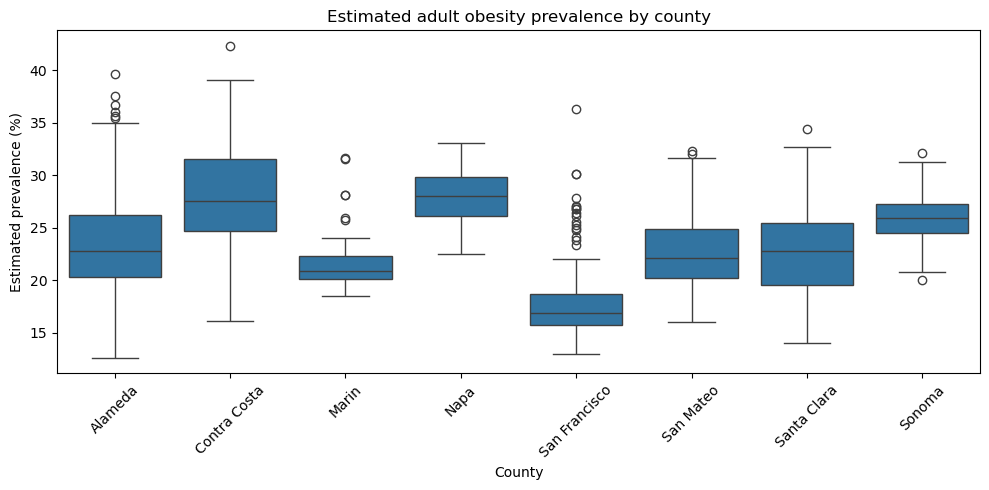

In [31]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=bay_health, x="countyname", y="obesity")
plt.xticks(rotation=45)
plt.xlabel("County")
plt.ylabel("Estimated prevalence (%)")
plt.title("Estimated adult obesity prevalence by county")
plt.tight_layout()
plt.show()

#### Diabetes boxplot

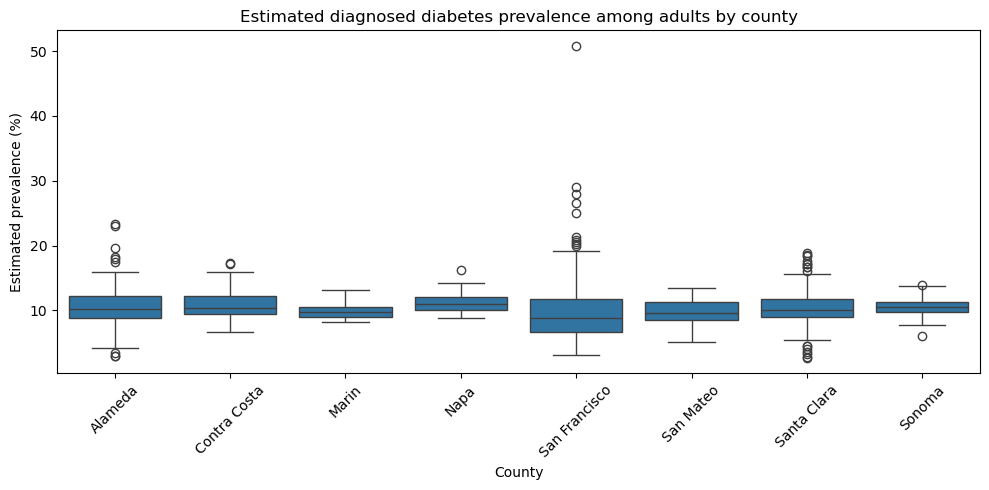

In [32]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=bay_health, x="countyname", y="diabetes")
plt.xticks(rotation=45)
plt.xlabel("County")
plt.ylabel("Estimated prevalence (%)")
plt.title("Estimated diagnosed diabetes prevalence among adults by county")
plt.tight_layout()
plt.show()

#### Coronary heart disease boxplot

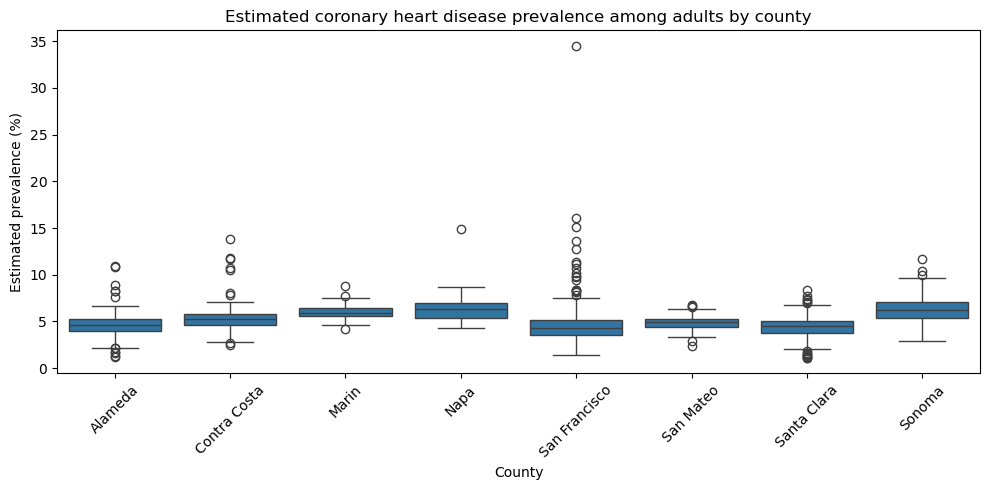

In [33]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=bay_health, x="countyname", y="coronary_heart_disease")
plt.xticks(rotation=45)
plt.xlabel("County")
plt.ylabel("Estimated prevalence (%)")
plt.title("Estimated coronary heart disease prevalence among adults by county")
plt.tight_layout()
plt.show()

#### Stroke boxplot

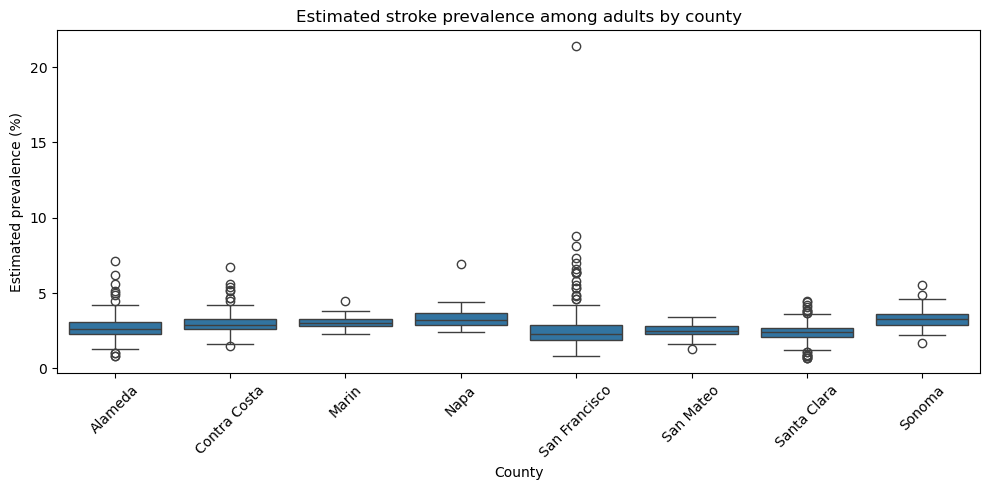

In [34]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=bay_health, x="countyname", y="stroke")
plt.xticks(rotation=45)
plt.xlabel("County")
plt.ylabel("Estimated prevalence (%)")
plt.title("Estimated stroke prevalence among adults by county")
plt.tight_layout()
plt.show()

#### High blood pressure boxplot

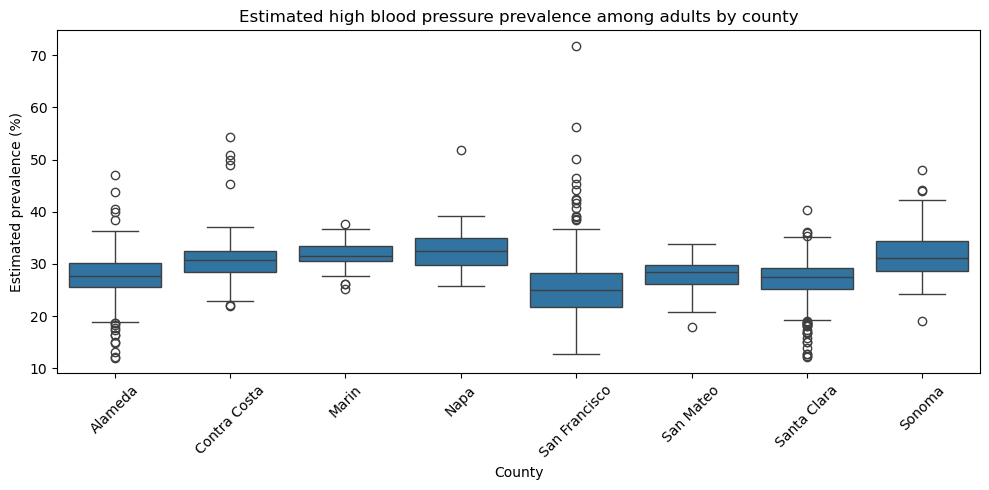

In [38]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=bay_health, x="countyname", y="high_blood_pressure")
plt.xticks(rotation=45)
plt.xlabel("County")
plt.ylabel("Estimated prevalence (%)")
plt.title("Estimated high blood pressure prevalence among adults by county")
plt.tight_layout()
plt.show()

### Health indicator distributions

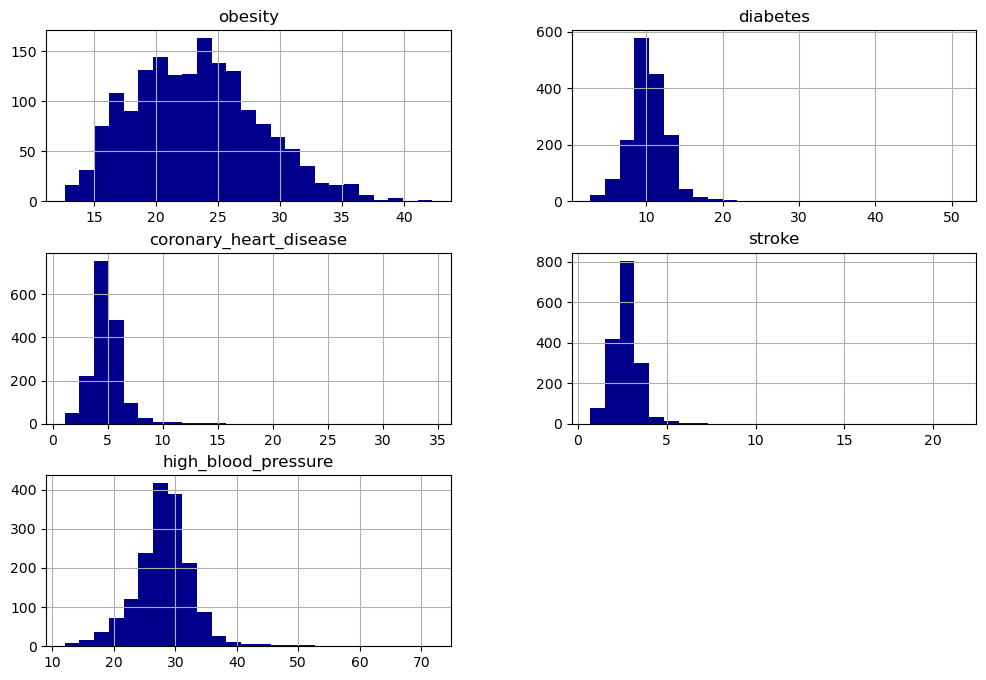

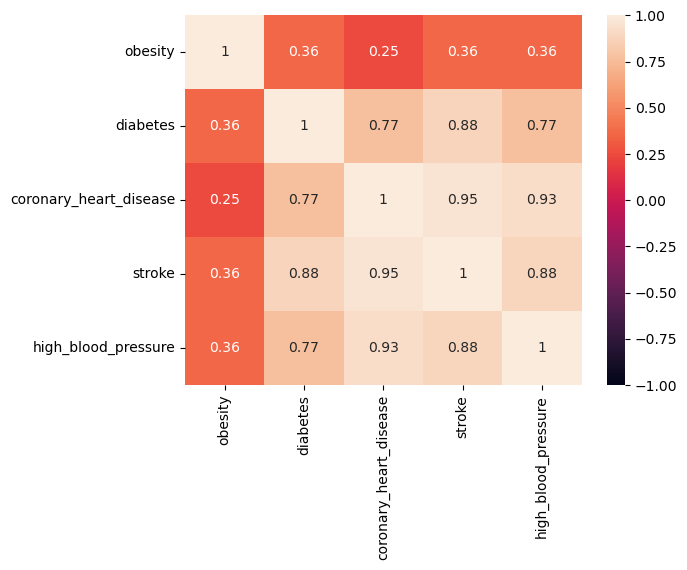

In [40]:
bay_health[indicators].hist(bins=25, figsize=(12, 8), color="darkblue")
plt.show()

sns.heatmap(
    bay_health[indicators].corr(),
    annot=True,
    vmin=-1,
    vmax=1
)
plt.show()

### Maps of health estimated by tract

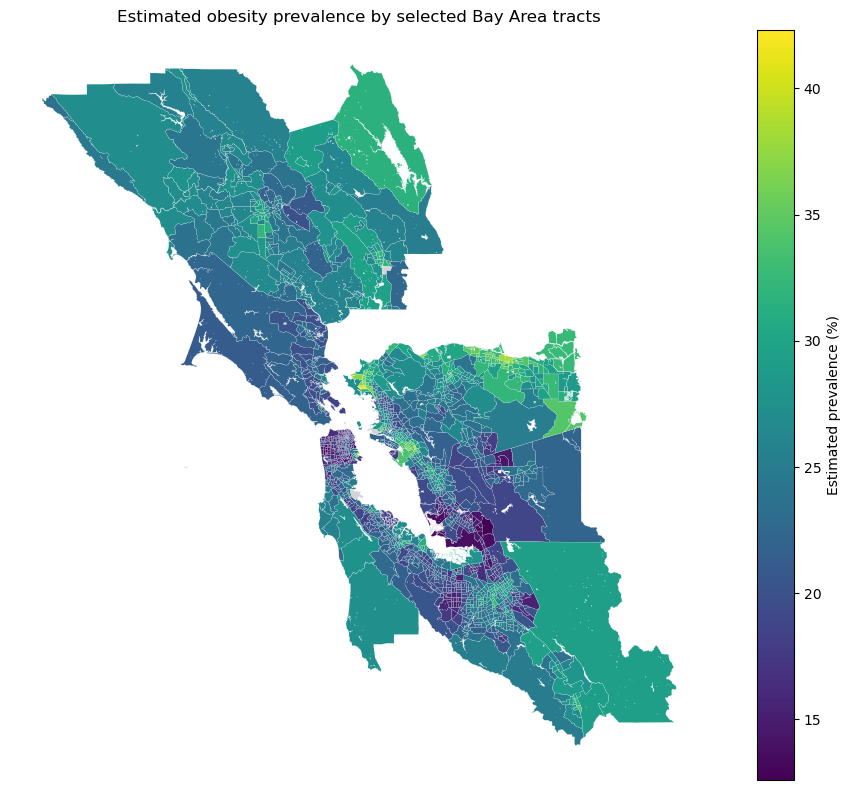

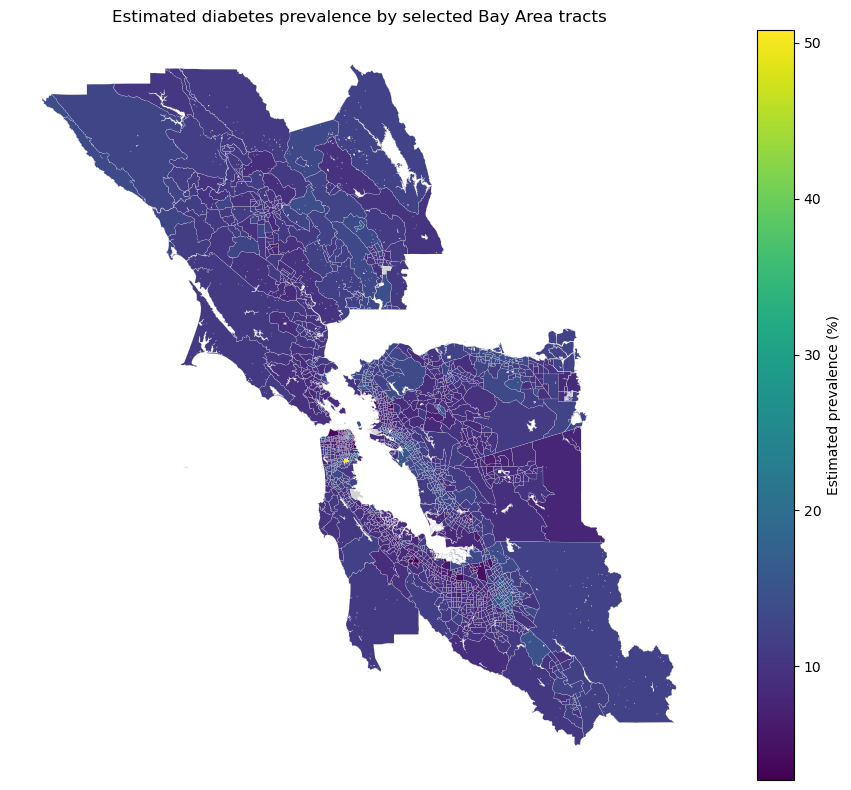

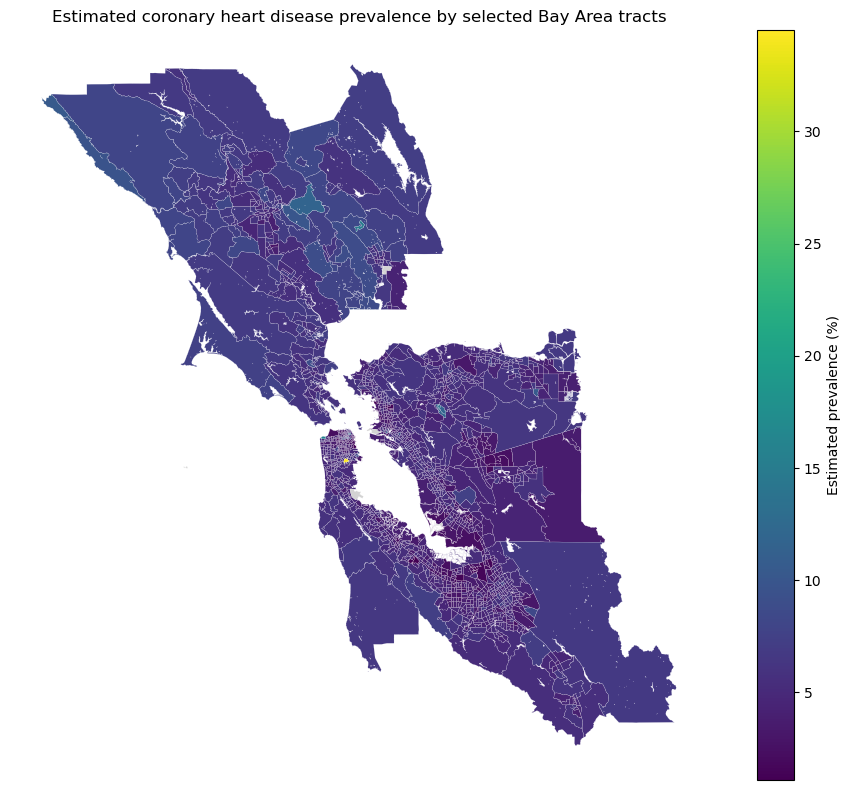

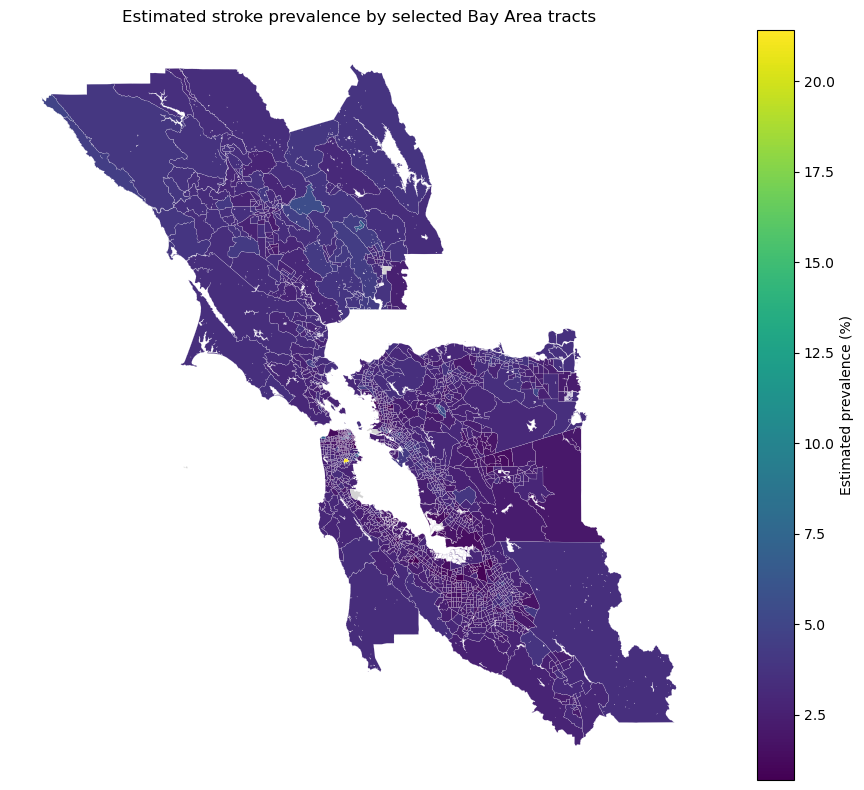

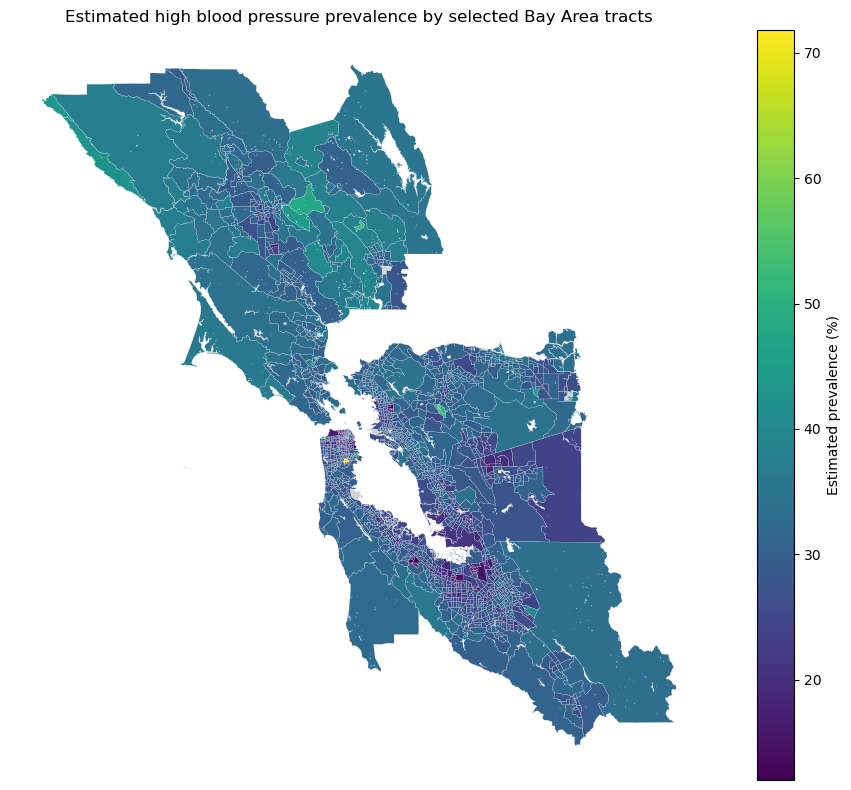

In [41]:
diseases = {
    "Obesity": "obesity",
    "Diabetes": "diabetes",
    "Coronary heart disease": "coronary_heart_disease",
    "Stroke": "stroke",
    "High blood pressure": "high_blood_pressure"
}

for title, column in diseases.items():
    fig, ax = plt.subplots(figsize=(10, 8))

    bay_health.plot(
        ax=ax,
        column=column,
        edgecolor="white",
        linewidth=0.1,
        legend=True,
        legend_kwds={"label": "Estimated prevalence (%)"},
        missing_kwds={"color": "lightgrey", "label": "No estimate"})

    ax.set_title(f"Estimated {title.lower()} prevalence by selected Bay Area tracts")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()